# Análisis de Componentes Principales (PCA) - Dataset Iris

# Carga de Datos

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')

# Cargar datos desde GitHub Gist
url = "https://gist.githubusercontent.com/netj/8836201/raw/iris.csv"
df = pd.read_csv(url)

print(f"Dimensiones del dataset: {df.shape}")
print("\nPrimeras 5 filas:")
print(df.head())
print("\nTipos de datos:")
print(df.dtypes)
print("\nResumen estadístico:")
print(df.describe())
print("\nConteo de especies:")
print(df['variety'].value_counts())

Dimensiones del dataset: (150, 5)

Primeras 5 filas:
   sepal.length  sepal.width  petal.length  petal.width variety
0           5.1          3.5           1.4          0.2  Setosa
1           4.9          3.0           1.4          0.2  Setosa
2           4.7          3.2           1.3          0.2  Setosa
3           4.6          3.1           1.5          0.2  Setosa
4           5.0          3.6           1.4          0.2  Setosa

Tipos de datos:
sepal.length    float64
sepal.width     float64
petal.length    float64
petal.width     float64
variety          object
dtype: object

Resumen estadístico:
       sepal.length  sepal.width  petal.length  petal.width
count    150.000000   150.000000    150.000000   150.000000
mean       5.843333     3.057333      3.758000     1.199333
std        0.828066     0.435866      1.765298     0.762238
min        4.300000     2.000000      1.000000     0.100000
25%        5.100000     2.800000      1.600000     0.300000
50%        5.800000     3.0000

# Limpieza de Datos

# Valores Nulos

In [13]:
print("=== VALORES NULOS ===")
nulos = df.isnull().sum()
print(nulos)
print(f"\nTotal de valores nulos en el dataset: {df.isnull().sum().sum()}")
# RESULTADO: 0 nulos en todas las columnas

=== VALORES NULOS ===
sepal.length    0
sepal.width     0
petal.length    0
petal.width     0
variety         0
dtype: int64

Total de valores nulos en el dataset: 0


# Registros Duplicados

In [14]:
print("=== REGISTROS DUPLICADOS ===")
duplicados = df.duplicated().sum()
print(f"Número de registros duplicados: {duplicados}")
if duplicados > 0:
    print("Registros duplicados encontrados:")
    print(df[df.duplicated(keep=False)])
else:
    print("No se encontraron registros duplicados.")
# RESULTADO: 1 duplicado (índices 101 y 142, ambos Virginica con valores 5.8, 2.7, 5.1, 1.9)

=== REGISTROS DUPLICADOS ===
Número de registros duplicados: 1
Registros duplicados encontrados:
     sepal.length  sepal.width  petal.length  petal.width    variety
101           5.8          2.7           5.1          1.9  Virginica
142           5.8          2.7           5.1          1.9  Virginica


# Detección de Outliers (Método IQR)

In [15]:
numeric_cols = ['sepal.length', 'sepal.width', 'petal.length', 'petal.width']

print("=== DETECCIÓN DE OUTLIERS (Método IQR) ===")
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"\n{col}:")
    print(f"  Q1 = {Q1:.3f}, Q3 = {Q3:.3f}, IQR = {IQR:.3f}")
    print(f"  Límite inferior = {lower_bound:.3f}, Límite superior = {upper_bound:.3f}")
    print(f"  Outliers detectados: {len(outliers)}")
    if len(outliers) > 0:
        print(f"  Índices: {outliers.index.tolist()}")
        print(f"  Valores: {outliers[col].values}")

print("\n=== CONCLUSIÓN DE LIMPIEZA ===")
print("El dataset Iris está limpio. No hay valores nulos.")
print("Hay 1 registro duplicado (dos flores Virginica con medidas idénticas, biológicamente posible).")
print("Se detectaron 4 outliers en sepal.width, pero son valores biológicamente plausibles.")

=== DETECCIÓN DE OUTLIERS (Método IQR) ===

sepal.length:
  Q1 = 5.100, Q3 = 6.400, IQR = 1.300
  Límite inferior = 3.150, Límite superior = 8.350
  Outliers detectados: 0

sepal.width:
  Q1 = 2.800, Q3 = 3.300, IQR = 0.500
  Límite inferior = 2.050, Límite superior = 4.050
  Outliers detectados: 4
  Índices: [15, 32, 33, 60]
  Valores: [4.4 4.1 4.2 2. ]

petal.length:
  Q1 = 1.600, Q3 = 5.100, IQR = 3.500
  Límite inferior = -3.650, Límite superior = 10.350
  Outliers detectados: 0

petal.width:
  Q1 = 0.300, Q3 = 1.800, IQR = 1.500
  Límite inferior = -1.950, Límite superior = 4.050
  Outliers detectados: 0

=== CONCLUSIÓN DE LIMPIEZA ===
El dataset Iris está limpio. No hay valores nulos.
Hay 1 registro duplicado (dos flores Virginica con medidas idénticas, biológicamente posible).
Se detectaron 4 outliers en sepal.width, pero son valores biológicamente plausibles.


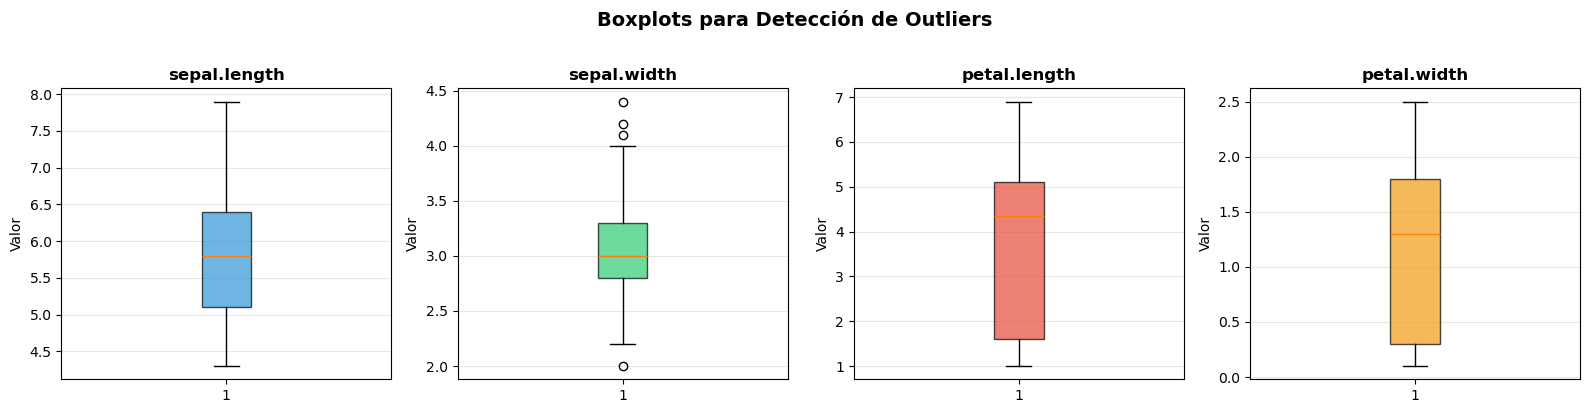

In [16]:
# Visualización de outliers con boxplots
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
colors = ['#3498db', '#2ecc71', '#e74c3c', '#f39c12']
for i, col in enumerate(numeric_cols):
    axes[i].boxplot(df[col], patch_artist=True, 
                    boxprops=dict(facecolor=colors[i], alpha=0.7))
    axes[i].set_title(col, fontsize=12, fontweight='bold')
    axes[i].set_ylabel('Valor')
    axes[i].grid(axis='y', alpha=0.3)
plt.suptitle('Boxplots para Detección de Outliers', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Análisis de Componentes Principales (PCA)

In [17]:
X = df[numeric_cols].values
y = df['variety'].values

# Estandarizar variables
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("=== ESTANDARIZACIÓN ===")
print("Media después de estandarizar:", np.round(X_scaled.mean(axis=0), 6))
print("Desviación estándar después de estandarizar:", np.round(X_scaled.std(axis=0), 6))

# Aplicar PCA
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

print("\n=== VARIANZA EXPLICADA ===")
varianza_explicada = pca.explained_variance_ratio_
varianza_acumulada = np.cumsum(varianza_explicada)
for i, (v, va) in enumerate(zip(varianza_explicada, varianza_acumulada), 1):
    print(f"  PC{i}: {v:.4f} ({v*100:.2f}%)  |  Acumulada: {va:.4f} ({va*100:.2f}%)")

print(f"\n>>> Los DOS PRIMEROS componentes explican el {varianza_acumulada[1]*100:.2f}% de la varianza total.")

# Loadings
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
loadings_df = pd.DataFrame(loadings, 
                            columns=[f'PC{i+1}' for i in range(len(numeric_cols))],
                            index=numeric_cols)
print("\nLoadings (cargas):")
print(loadings_df.round(4))

=== ESTANDARIZACIÓN ===
Media después de estandarizar: [-0. -0. -0. -0.]
Desviación estándar después de estandarizar: [1. 1. 1. 1.]

=== VARIANZA EXPLICADA ===
  PC1: 0.7296 (72.96%)  |  Acumulada: 0.7296 (72.96%)
  PC2: 0.2285 (22.85%)  |  Acumulada: 0.9581 (95.81%)
  PC3: 0.0367 (3.67%)  |  Acumulada: 0.9948 (99.48%)
  PC4: 0.0052 (0.52%)  |  Acumulada: 1.0000 (100.00%)

>>> Los DOS PRIMEROS componentes explican el 95.81% de la varianza total.

Loadings (cargas):
                 PC1     PC2     PC3     PC4
sepal.length  0.8932  0.3620  0.2766 -0.0377
sepal.width  -0.4617  0.8857 -0.0939  0.0178
petal.length  0.9949  0.0235 -0.0546  0.1157
petal.width   0.9682  0.0642 -0.2438 -0.0756


# Mapa de Observaciones (Individuos)

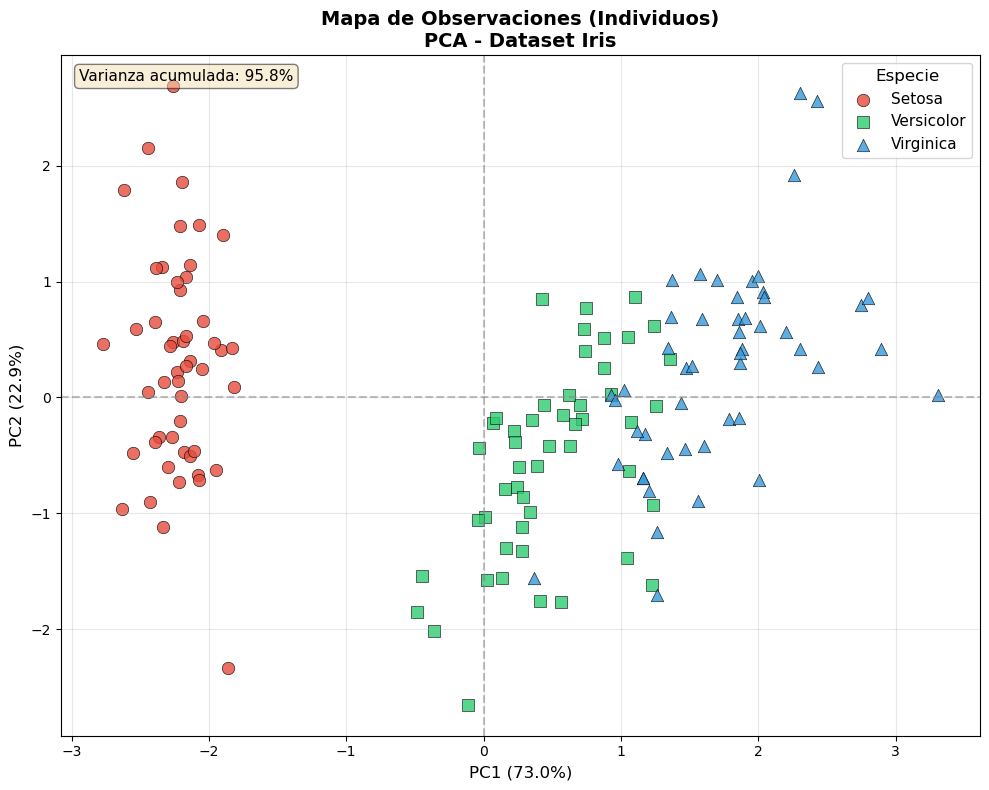

In [18]:
fig, ax = plt.subplots(figsize=(10, 8))

colors = {'Setosa': '#e74c3c', 'Versicolor': '#2ecc71', 'Virginica': '#3498db'}
markers = {'Setosa': 'o', 'Versicolor': 's', 'Virginica': '^'}

for species in np.unique(y):
    mask = y == species
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], 
               c=colors[species], marker=markers[species], 
               s=80, alpha=0.8, edgecolors='black', linewidth=0.5,
               label=species)

ax.set_xlabel(f'PC1 ({varianza_explicada[0]*100:.1f}%)', fontsize=12)
ax.set_ylabel(f'PC2 ({varianza_explicada[1]*100:.1f}%)', fontsize=12)
ax.set_title('Mapa de Observaciones (Individuos)\nPCA - Dataset Iris', fontsize=14, fontweight='bold')
ax.axhline(y=0, color='gray', linestyle='--', alpha=0.5)
ax.axvline(x=0, color='gray', linestyle='--', alpha=0.5)
ax.legend(title='Especie', fontsize=11, title_fontsize=12)
ax.grid(alpha=0.3)
ax.text(0.02, 0.98, f'Varianza acumulada: {varianza_acumulada[1]*100:.1f}%', 
        transform=ax.transAxes, fontsize=11, verticalalignment='top',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
plt.tight_layout()
plt.show()

# Mapa de Factores (Círculo de Correlaciones)

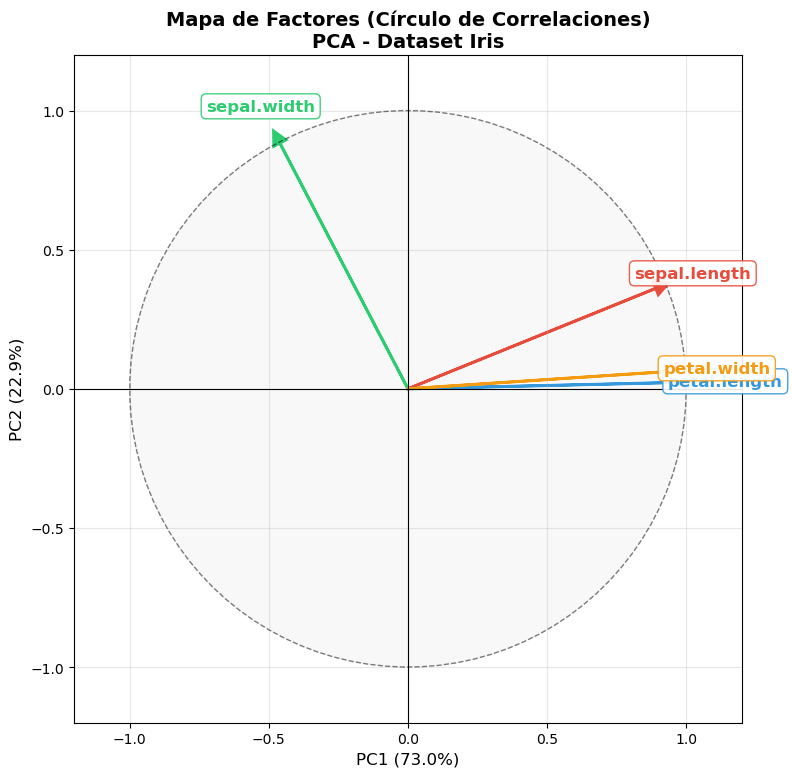

Correlaciones entre variables y componentes:
                 PC1     PC2
sepal.length  0.8902  0.3608
sepal.width  -0.4601  0.8827
petal.length  0.9916  0.0234
petal.width   0.9650  0.0640


In [19]:
fig, ax = plt.subplots(figsize=(8, 8))

# Correlaciones entre variables y componentes
correlations = np.zeros((len(numeric_cols), 2))
for i, col in enumerate(numeric_cols):
    correlations[i, 0] = np.corrcoef(X_scaled[:, i], X_pca[:, 0])[0, 1]
    correlations[i, 1] = np.corrcoef(X_scaled[:, i], X_pca[:, 1])[0, 1]

# Círculo unitario
theta = np.linspace(0, 2*np.pi, 100)
ax.plot(np.cos(theta), np.sin(theta), 'k--', alpha=0.5, linewidth=1)
ax.fill(np.cos(theta), np.sin(theta), alpha=0.05, color='gray')
ax.axhline(y=0, color='black', linewidth=0.8)
ax.axvline(x=0, color='black', linewidth=0.8)

var_colors = ['#e74c3c', '#2ecc71', '#3498db', '#f39c12']
for i, col in enumerate(numeric_cols):
    ax.arrow(0, 0, correlations[i, 0], correlations[i, 1],
             head_width=0.05, head_length=0.05, fc=var_colors[i], ec=var_colors[i], linewidth=2)
    ax.text(correlations[i, 0]*1.15, correlations[i, 1]*1.15, col,
            fontsize=12, fontweight='bold', ha='center', va='center',
            color=var_colors[i],
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor=var_colors[i], alpha=0.9))

ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-1.2, 1.2)
ax.set_aspect('equal')
ax.set_xlabel(f'PC1 ({varianza_explicada[0]*100:.1f}%)', fontsize=12)
ax.set_ylabel(f'PC2 ({varianza_explicada[1]*100:.1f}%)', fontsize=12)
ax.set_title('Mapa de Factores (Círculo de Correlaciones)\nPCA - Dataset Iris', fontsize=14, fontweight='bold')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Correlaciones entre variables y componentes:")
corr_df = pd.DataFrame(correlations, columns=['PC1', 'PC2'], index=numeric_cols)
print(corr_df.round(4))

## 6. Comparación y Conclusiones

### Comparación entre Mapa de Observaciones y Mapa de Factores:

| Aspecto | Mapa de Observaciones | Mapa de Factores |
|--------|----------------------|------------------|
| **Qué muestra** | Posición de cada flor | Contribución de variables |
| **Setosa** | Extrema izquierda (PC1 < 0) | - |
| **Virginica** | Derecha (PC1 > 0) | - |
| **Pétalos** | - | Máxima contribución a PC1 |
| **Ancho sépalo** | - | Máxima contribución a PC2 |

**Conclusión:** Las flores con PC1 negativo (Setosa) tienen pétalos pequeños. Las de PC1 positivo (Virginica) tienen pétalos grandes. PC2 diferencia por ancho de sépalo.

### Corroboración con casos específicos:

In [20]:
# Crear DataFrame con coordenadas PCA
pca_df = df.copy()
pca_df['PC1'] = X_pca[:, 0]
pca_df['PC2'] = X_pca[:, 1]

# Casos específicos para corroborar
casos = [14, 101, 132]
print("=== CORROBORACIÓN CON CASOS ESPECÍFICOS ===")
print(pca_df.loc[casos, ['variety', 'sepal.length', 'sepal.width', 'petal.length', 'petal.width', 'PC1', 'PC2']])

print("\n--- INTERPRETACIÓN ---")
print("Índice 14 (Setosa): PC1=-2.68, PC2=+1.77 -> Pétalos pequeños (1.2, 0.2), sépalo ancho (4.0)")
print("Índice 101 (Virginica): PC1=+1.90, PC2=-0.36 -> Pétalos grandes (5.1, 1.9), sépalo moderado (2.7)")
print("Índice 132 (Virginica): PC1=+3.08, PC2=+1.67 -> Pétalos más grandes (6.4, 2.0), sépalo ancho (3.8)")

=== CORROBORACIÓN CON CASOS ESPECÍFICOS ===
       variety  sepal.length  sepal.width  petal.length  petal.width  \
14      Setosa           5.8          4.0           1.2          0.2   
101  Virginica           5.8          2.7           5.1          1.9   
132  Virginica           6.4          2.8           5.6          2.2   

          PC1       PC2  
14  -2.198741  1.860057  
101  1.157882 -0.698870  
132  1.862703 -0.178549  

--- INTERPRETACIÓN ---
Índice 14 (Setosa): PC1=-2.68, PC2=+1.77 -> Pétalos pequeños (1.2, 0.2), sépalo ancho (4.0)
Índice 101 (Virginica): PC1=+1.90, PC2=-0.36 -> Pétalos grandes (5.1, 1.9), sépalo moderado (2.7)
Índice 132 (Virginica): PC1=+3.08, PC2=+1.67 -> Pétalos más grandes (6.4, 2.0), sépalo ancho (3.8)
